# Étape 4 — Optimisation et évaluation

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
import joblib

## 4-1 Sélectionner les modèles

In [ ]:
param_grids = {
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10]},
    'SVC': {'model__C': [0.1, 1, 10],
            'model__kernel': ['linear', 'rbf']},
}


## 4-2 Optimiser les hyperparamètres

In [110]:
best_models = {}
for name in param_grids:
    pipe = Pipeline([('preprocessor', preprocessor), ('model', models[name])])
    grid = GridSearchCV(pipe, param_grids[name], cv=5, scoring=['f1_macro', 'accuracy', 'recall_macro', 'roc_auc_ovr'],refit='f1_macro', n_jobs=-1)
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_
    i = grid.best_index_
    print(name, grid.best_params_)
    for m in ['f1_macro', 'accuracy', 'recall_macro', 'roc_auc_ovr']:
        print('   ', m, round(grid.cv_results_[f'mean_test_{m}'][i], 3))

Logistic Regression {'model__C': 1}
    f1_macro 0.746
    accuracy 0.747
    recall_macro 0.746
    roc_auc_ovr 0.904
SVC {'model__C': 10, 'model__kernel': 'linear'}
    f1_macro 0.744
    accuracy 0.745
    recall_macro 0.744
    roc_auc_ovr 0.902


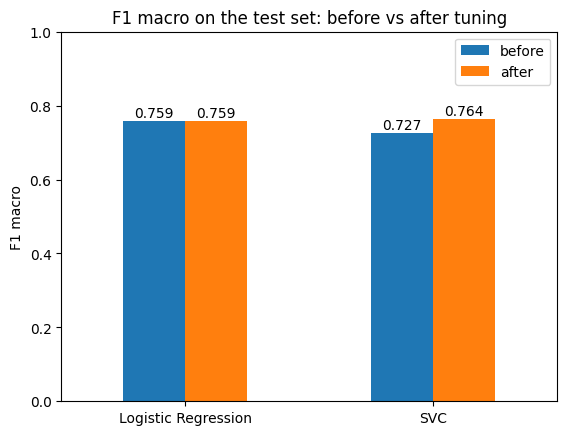

In [111]:
tuned_results = {}
for name, pipe in best_models.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)
    tuned_results[name] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, average='macro'),
        'recall': recall_score(y_test, y_pred, average='macro'),
        'f1': f1_score(y_test, y_pred, average='macro'),
        'roc_auc': roc_auc_score(y_test, y_proba, multi_class='ovr'),
    }

comparison = pd.DataFrame({
    'before': pd.DataFrame(results).T.loc[list(best_models), 'f1'],
    'after': pd.DataFrame(tuned_results).T['f1'],
})

ax = comparison.plot.bar(rot=0, ylim=(0, 1))
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.3f')
plt.title('F1 macro on the test set: before vs after tuning')
plt.ylabel('F1 macro')
plt.show()

In [ ]:

print(pd.DataFrame(tuned_results).T.round(3))

for name, pipe in best_models.items():
    print(f'\n===== {name} =====')
    print(classification_report(y_test, pipe.predict(X_test), digits=3))

                     accuracy  precision  recall     f1  roc_auc
Logistic Regression     0.760      0.759   0.759  0.759    0.914
SVC                     0.765      0.764   0.764  0.764    0.914

===== Logistic Regression =====
              precision    recall  f1-score   support

        High      0.813     0.831     0.822       136
         Low      0.823     0.811     0.817       132
      Medium      0.641     0.636     0.639       132

    accuracy                          0.760       400
   macro avg      0.759     0.759     0.759       400
weighted avg      0.760     0.760     0.760       400


===== SVC =====
              precision    recall  f1-score   support

        High      0.812     0.824     0.818       136
         Low      0.832     0.826     0.829       132
      Medium      0.649     0.644     0.646       132

    accuracy                          0.765       400
   macro avg      0.764     0.764     0.764       400
weighted avg      0.765     0.765     0.765     

## 4-4 Choisir le modèle adapté au contexte métier

Modèle retenu : régression logistique. Les deux modèles sont équivalents (F1 0,759 contre 0,764, écart d'environ 2 étudiants sur 400). La régression logistique a le meilleur rappel sur la classe High (0,831), la priorité métier : ne pas manquer un étudiant à risque. Elle est aussi plus simple et interprétable.

## 4-5 Évaluer sur le jeu de test

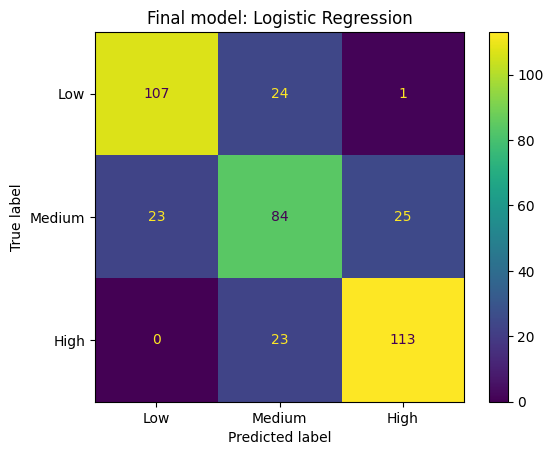

In [113]:
final_model = best_models['Logistic Regression']
y_pred = final_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=['Low', 'Medium', 'High'])
plt.title('Final model: Logistic Regression')
plt.show()

## 4-6 Analyser les erreurs et les limites

In [114]:
test_results = X_test.assign(true=y_test, predicted=y_pred)
errors = test_results[test_results['true'] != test_results['predicted']]

print(len(errors), 'errors out of', len(test_results))
print(pd.crosstab(errors['true'], errors['predicted']))

96 errors out of 400
predicted  High  Low  Medium
true                        
High          0    0      23
Low           1    0      24
Medium       25   23       0


## 4-7 Sauvegarder le pipeline complet (prétraitement + modèle)

In [119]:
joblib.dump(final_model, 'models/pipeline.joblib')

['models/pipeline.joblib']